In [14]:
import numpy as np
import random
import heapq, math
from collections import defaultdict
import matplotlib.pyplot as plt
import networkx as nx

In [15]:
n = 7
m = 17

In [16]:
def generate_random_graph(num_vertices = n, num_edges = m, min_weight=1.0, max_weight=20.0, directed=False):
    edges = set()
    pairs = set()
    
    while len(edges) < num_edges:
        u = random.randint(1, num_vertices)
        v = random.randint(1, num_vertices)
        
        if u == v:
            continue
 
        if {u, v} == {1, 7}:
            continue
        
        if not directed and (v, u) in edges:
            continue

        pair = (u, v) if directed else (min(u, v), max(u, v))
        if pair in pairs:
            continue
        pairs.add(pair)

        weight = random.uniform(min_weight, max_weight)
        edges.add((u, v, weight))
    
    return list(edges)
g1 = generate_random_graph(n, m, min_weight=1.0, max_weight=20.0, directed=False)
display(g1)



[(7, 4, 9.551698296685402),
 (5, 4, 11.438028239370974),
 (3, 1, 1.1481004730877924),
 (4, 2, 4.606932899236595),
 (5, 6, 17.167655000883133),
 (1, 6, 17.54143805052255),
 (6, 4, 17.3474067439152),
 (4, 1, 12.393451823291638),
 (2, 7, 17.5602689203217),
 (2, 3, 2.7697074952098704),
 (6, 7, 4.116636669567864),
 (2, 1, 3.0199580896669027),
 (4, 3, 10.868451436925774),
 (3, 6, 1.3700863055307102),
 (5, 7, 10.425314409017778),
 (5, 2, 12.128221894627519),
 (1, 5, 12.552336381495905)]

In [17]:
def dijkstra(edges, start=1):
    graph = defaultdict(list)

    for u, v, w in edges:
        graph[u].append((v, w))
        graph[v].append((u, w)) 


    distances = {start: 0}
    previous = {start: None}
    queue = [(0, start)]

    while queue:
        current_distance, current_vertex = heapq.heappop(queue)

        if current_distance > distances.get(current_vertex, float("inf")):
            continue

        for neighbor, weight in graph[current_vertex]:
            distance = current_distance + weight

            if distance < distances.get(neighbor, float("inf")):
                distances[neighbor] = distance
                previous[neighbor] = current_vertex

                heapq.heappush(queue, (distance, neighbor))

    vertices = set()
    for u, v, w in edges:
        vertices.add(u)
        vertices.add(v)

    vertices.add(start)

    results = {}

    for vertex in sorted(vertices):
        if vertex not in distances:
            results[vertex] = (None, float("inf"))
            continue

        path = []
        current_vertex = vertex

        while current_vertex is not None:
            path.append(current_vertex)
            current_vertex = previous[current_vertex]

        path.reverse()

        results[vertex] = (path, distances[vertex])

    return results



results = dijkstra(g1, start=1)




for vertex, (path, distance) in results.items():
    print(f"Destination: {vertex}")
    print(f"Min Distance: {distance:.2f}")
    print(f"Shortest Route: {path}")
    print("------------------------------")


Destination: 1
Min Distance: 0.00
Shortest Route: [1]
------------------------------
Destination: 2
Min Distance: 3.02
Shortest Route: [1, 2]
------------------------------
Destination: 3
Min Distance: 1.15
Shortest Route: [1, 3]
------------------------------
Destination: 4
Min Distance: 7.63
Shortest Route: [1, 2, 4]
------------------------------
Destination: 5
Min Distance: 12.55
Shortest Route: [1, 5]
------------------------------
Destination: 6
Min Distance: 2.52
Shortest Route: [1, 3, 6]
------------------------------
Destination: 7
Min Distance: 6.63
Shortest Route: [1, 3, 6, 7]
------------------------------


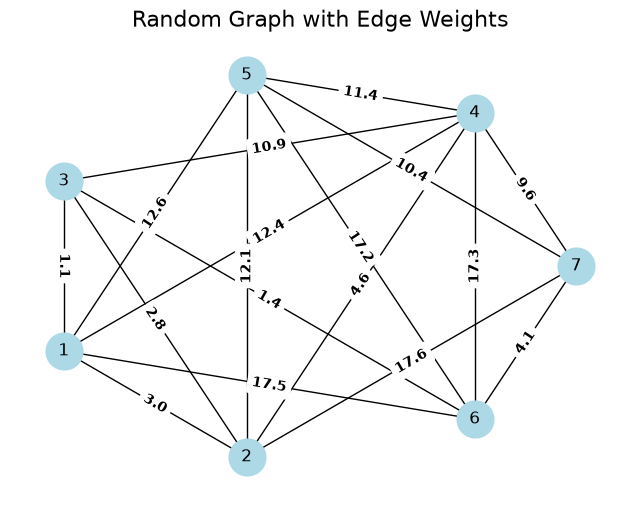

In [18]:
G = nx.Graph()
for u, v, w in g1:
    G.add_edge(u, v, weight=w)

pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(8, 6))

nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=700, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
nx.draw_networkx_edges(G, pos, ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{w:.1f}" for u, v, w in g1}, font_size=10, font_weight='bold', ax=ax)

ax.set_title("Random Graph with Edge Weights", fontsize=16)
ax.axis('off')

plt.show()